In [1]:
import pandas as pd
import math
from collections import Counter
from nltk.util import bigrams, trigrams, ngrams

df = pd.read_csv('IndoLeX_Database_preprocessed.csv')
text_column = "processed_text"  # gunakan hasil preprocessing
df = df.dropna(subset=[text_column])
print(f"Jumlah dokumen: {len(df)}")

all_text = " ".join(df[text_column].astype(str))
tokens = all_text.split()
print(f"Total token: {len(tokens)}")
print(f"Contoh token: {tokens[:20]}")

unigram = Counter(tokens)
print("20 Kata Paling Sering Muncul:")
for word, count in unigram.most_common(20):
    print(f"  {word:<20} : {count}")

total_tokens = sum(unigram.values())
unigram_probability = {
    word: count / total_tokens
    for word, count in unigram.items()
}
print("\n10 Kata dengan Probabilitas Tertinggi:")
sorted_prob = sorted(
    unigram_probability.items(),
    key=lambda x: x[1],
    reverse=True
)
for word, prob in sorted_prob[:10]:
    print(f"  {word:<20} : {prob:.6f}")

bigram_tokens = list(bigrams(tokens))
bigram_frequency = Counter(bigram_tokens)

print("20 Bigram Paling Sering Muncul:")
for bigram, count in bigram_frequency.most_common(20):
    print(f"  {' '.join(bigram):<30} : {count}")

Jumlah dokumen: 131494
Total token: 131494
Contoh token: ['aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba', 'aba']
20 Kata Paling Sering Muncul:
  ajar                 : 107
  laku                 : 90
  tahan                : 84
  dapat                : 79
  kerja                : 79
  tuju                 : 77
  diri                 : 76
  jalan                : 74
  buat                 : 72
  daya                 : 72
  kenal                : 71
  temu                 : 71
  ingat                : 70
  duduk                : 69
  guna                 : 69
  baik                 : 68
  satu                 : 67
  pikir                : 65
  kembang              : 64
  tinggal              : 63

10 Kata dengan Probabilitas Tertinggi:
  ajar                 : 0.000814
  laku                 : 0.000684
  tahan                : 0.000639
  dapat                : 0.000601
  kerja                : 0.000601
 

In [2]:
trigram_tokens = list(trigrams(tokens))
trigram_frequency = Counter(trigram_tokens)

print("20 Trigram Paling Sering Muncul:")
for trigram, count in trigram_frequency.most_common(20):
    print(f"  {' '.join(trigram):<40} : {count}")

def bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)]
    denominator = unigram[word1]
    if denominator == 0:
        return 0.0
    return numerator / denominator
# Contoh
word1, word2 = "belajar", "nlp"
prob = bigram_probability(word1, word2)
print(f"P({word2} | {word1}) = {prob:.6f}")

def sentence_probability(sentence):
    words = sentence.lower().split()
    probability = 1.0

    for i in range(len(words) - 1):
        p = bigram_probability(words[i], words[i + 1])
        probability *= p

    return probability
# Uji
test_sentences = [
    "saya belajar nlp",
    "nlp menarik sekali",
    "model bahasa sederhana",
]
for sentence in test_sentences:
    p = sentence_probability(sentence)
    print(f"P('{sentence}') = {p:.8f}")

vocab_size = len(unigram)

def smoothed_bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)] + 1
    denominator = unigram[word1] + vocab_size
    return numerator / denominator

# Uji dengan kata yang mungkin tidak ada dalam corpus
word1, word2 = "deep", "learning"
prob = smoothed_bigram_probability(word1, word2)
print(f"Smoothed P({word2} | {word1}) = {prob:.8f}")

vocab_size = len(unigram)
def smoothed_bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)] + 1
    denominator = unigram[word1] + vocab_size
    return numerator / denominator
# Uji dengan kata yang mungkin tidak ada dalam corpus
word1, word2 = "deep", "learning"
prob = smoothed_bigram_probability(word1, word2)
print(f"Smoothed P({word2} | {word1}) = {prob:.8f}")

vocab_size = len(unigram)
def smoothed_bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)] + 1
    denominator = unigram[word1] + vocab_size
    return numerator / denominator
# Uji dengan kata yang mungkin tidak ada dalam corpus
word1, word2 = "deep", "learning"
prob = smoothed_bigram_probability(word1, word2)
print(f"Smoothed P({word2} | {word1}) = {prob:.8f}")

def predict_next_word(context_word, top_n=5):
    candidates = []
    for (word1, word2), count in bigram_frequency.items():
        if word1 == context_word:
            p = smoothed_bigram_probability(word1, word2)
            candidates.append((word2, p))
    candidates.sort(key=lambda x: x[1], reverse=True)
    return candidates[:top_n]
# Contoh
context = "belajar"
predictions = predict_next_word(context)
print(f"\nPrediksi kata setelah '{context}':")
for word, prob in predictions:
    print(f"  {word:<20} : {prob:.6f}")

20 Trigram Paling Sering Muncul:
  ajar ajar ajar                           : 105
  laku laku laku                           : 88
  tahan tahan tahan                        : 82
  dapat dapat dapat                        : 77
  kerja kerja kerja                        : 77
  tuju tuju tuju                           : 75
  diri diri diri                           : 74
  jalan jalan jalan                        : 72
  buat buat buat                           : 70
  daya daya daya                           : 70
  kenal kenal kenal                        : 69
  temu temu temu                           : 69
  ingat ingat ingat                        : 68
  duduk duduk duduk                        : 67
  guna guna guna                           : 67
  baik baik baik                           : 66
  satu satu satu                           : 65
  pikir pikir pikir                        : 63
  kembang kembang kembang                  : 62
  tinggal tinggal tinggal                  : 61
P(nlp 

Kalimat : 'saya belajar nlp'
P(W)    : 0.00000000
N       : 3
PP(W)   : inf
PERBANDINGAN MODEL N-GRAM
Ukuran Vocabulary     : 27,183
Jumlah Token          : 131,494
Jumlah Unigram unik   : 27,183
Jumlah Bigram unik    : 44,423
Jumlah Trigram unik   : 56,932

Kemungkinan Bigram maks  : 738,915,489
Bigram yang ada          : 44,423
Bigram coverage          : 0.0060%


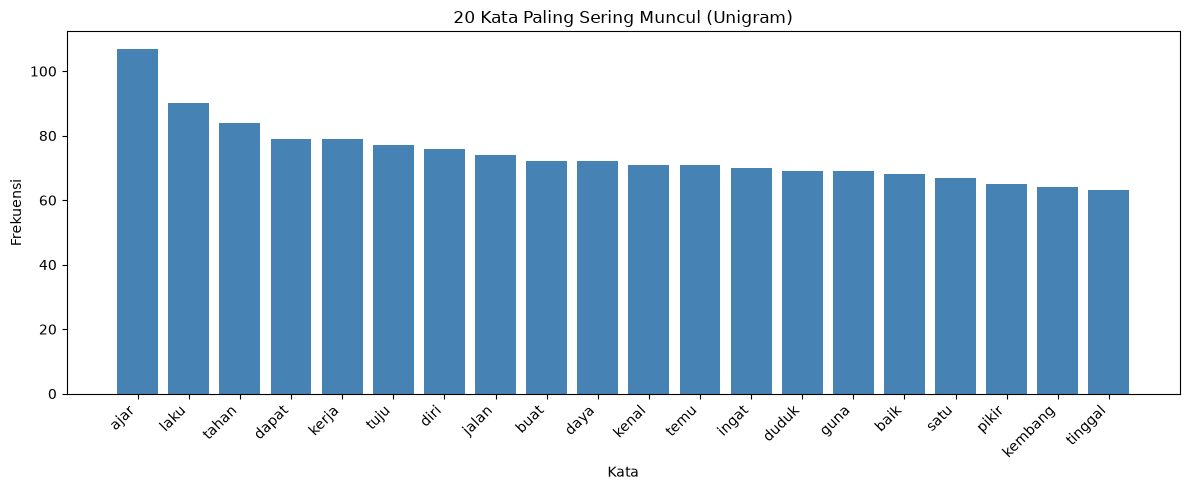

In [3]:
def perplexity(probability, N):
    if probability == 0 or probability is None:
        return float("inf")
    return probability ** (-1 / N)
sentence = "saya belajar nlp"
words = sentence.split()
prob = sentence_probability(sentence)
N = len(words)
pp = perplexity(prob, N)
print(f"Kalimat : '{sentence}'")
print(f"P(W)    : {prob:.8f}")
print(f"N       : {N}")
print(f"PP(W)   : {pp:.4f}")
print("=" * 60)
print("PERBANDINGAN MODEL N-GRAM")
print("=" * 60)
print(f"Ukuran Vocabulary     : {len(unigram):,}")
print(f"Jumlah Token          : {len(tokens):,}")
print(f"Jumlah Unigram unik   : {len(unigram):,}")
print(f"Jumlah Bigram unik    : {len(bigram_frequency):,}")
print(f"Jumlah Trigram unik   : {len(trigram_frequency):,}")
print()
# Cek sparsity
max_bigram = len(unigram) ** 2
max_trigram = len(unigram) ** 3
print(f"Kemungkinan Bigram maks  : {max_bigram:,}")
print(f"Bigram yang ada          : {len(bigram_frequency):,}")
print(f"Bigram coverage          : {len(bigram_frequency)/max_bigram*100:.4f}%")

import matplotlib.pyplot as plt
# Top 20 unigram
top_words = unigram.most_common(20)
words_list = [w[0] for w in top_words]
counts_list = [w[1] for w in top_words]
plt.figure(figsize=(12, 5))
plt.bar(words_list, counts_list, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi")
plt.title("20 Kata Paling Sering Muncul (Unigram)")
plt.tight_layout()
plt.show()